# Single Fidelity MLP Comparison

This workbook trains `SurrogateModels.mfsnn.MLPNetwork` over 2D, 4D, 6D, 8D, and 10D analytical test functions, sweeping sample count to compare accuracy and cost -- same structure as `SingleFidelityComparison_KAN.ipynb` and `SingleFidelityComparison_Kriging.ipynb`.

Helper functions live in `examples/single_fidelity_nn_helpers.py`.

(Note: there's a pre-existing `SingleFidelityComparison_NN.ipynb` in this folder from earlier exploration -- it predates `single_fidelity_nn_helpers.py` and has its own inline, duplicated version of these functions plus a handful of ad hoc exploratory models. Left untouched; this notebook is a separate, from-scratch build using the shared helper module.)

**Sample ranges:** unlike the Kriging notebook, these reuse the *same* ranges as the KAN notebook (up to `n=4000` for 8D) rather than cut-down ones -- `MLPNetwork`'s AdamW/epoch-based training scales far more gracefully with sample count than Kriging's per-iteration Cholesky decomposition does. Spot-checked at 8D (the most expensive case elsewhere): `n=100` -> 11s, `n=1000` -> 22s, `n=4000` -> 78s, nothing like Kriging's multi-hour blowup at similar `n`.

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from examples import single_fidelity_nn_helpers as nn_helpers


### 2-Dimensional Dataset

In [3]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)


In [ ]:
points_2d = []
model_error_2d = []
training_time_2d = []
evaluation_time_2d = []
points_2d, model_error_2d, evaluation_time_2d, training_time_2d = nn_helpers.generate_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=50,
    sample_high=1051,
    step_size=100,
    seeds=3,
    points=points_2d,
    model_error=model_error_2d,
    training_time=training_time_2d,
    evaluation_time=evaluation_time_2d,
    hidden_layer_size=[30, 30, 10],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=30000,
    output_file="nn_model_comparison_2d.csv",
)
ax = nn_helpers.plot_error_measure(points_2d, model_error_2d, "2D MLP Error vs Samples")
nn_helpers.save_plot(ax, "2D_sweep_mlp")
plt.show()


Run 2D :: seed 0 :: points 50 :: error 1.4861138620395047 :: train_time 197.63109049999912 
Run 2D :: seed 0 :: points 100 :: error 0.8147417597141936 :: train_time 215.67694979999214 
Run 2D :: seed 0 :: points 150 :: error 0.17408371266935405 :: train_time 240.5857241999911 
Run 2D :: seed 0 :: points 200 :: error 0.09461244176972565 :: train_time 272.3944427000097 
Run 2D :: seed 0 :: points 250 :: error 0.06115653783138896 :: train_time 289.80799839999236 
Run 2D :: seed 0 :: points 300 :: error 0.044136678501061934 :: train_time 312.37687089999963 
Run 2D :: seed 0 :: points 350 :: error 0.032704674948448725 :: train_time 343.21281690000615 
Run 2D :: seed 0 :: points 400 :: error 0.027456068357298025 :: train_time 365.0635575000051 
Run 2D :: seed 0 :: points 450 :: error 0.027884229759183334 :: train_time 386.6187128000165 
Run 2D :: seed 0 :: points 500 :: error 0.03126629228660096 :: train_time 464.5528508000134 
Run 2D :: seed 0 :: points 550 :: error 0.022641748632146696 :: 

KeyboardInterrupt: 

### 4-Dimensional Dataset

In [7]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)


In [ ]:
# Spot check: single n=1000 run with the same settings as the 4D sweep below
model_4d_check, error_4d_check, train_time_4d_check, eval_time_4d_check = nn_helpers.generate_nn_model(
    key,
    my_function,
    n=1000,
    seed=0,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[30, 30, 10],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=30000,
)
model_4d_check.plot_training_error("4D MLP Spot Check (n=1000) Training History")
plt.show()

Run 10D :: seed 0 :: points 100 :: error 5.450249563293238 :: train_time 220.07817709998926 
Run 10D :: seed 0 :: points 200 :: error 1.1889576208974788 :: train_time 274.7171445999993 
Run 10D :: seed 0 :: points 300 :: error 0.5987791245830774 :: train_time 312.9239367999835 
Run 10D :: seed 0 :: points 400 :: error 0.5019492055784812 :: train_time 361.4149741999572 
Run 10D :: seed 0 :: points 500 :: error 0.27252788901513814 :: train_time 402.9045991000021 
Run 10D :: seed 0 :: points 600 :: error 0.17547177442908465 :: train_time 493.0121916999924 
Run 10D :: seed 0 :: points 700 :: error 0.19216049670435717 :: train_time 596.8591577000334 
Run 10D :: seed 0 :: points 800 :: error 0.17806403236788074 :: train_time 630.7089812000049 
Run 10D :: seed 0 :: points 900 :: error 0.12762693068827738 :: train_time 700.788731800043 
Run 10D :: seed 0 :: points 1000 :: error 0.12247945680234902 :: train_time 746.5228111000033 
Run 10D :: seed 1 :: points 100 :: error 5.04314334909333 :: tra

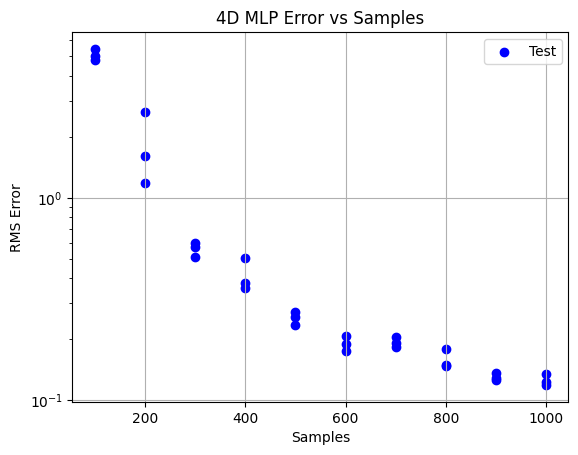

In [16]:
points_4d = []
model_error_4d = []
training_time_4d = []
evaluation_time_4d = []
points_4d, model_error_4d, evaluation_time_4d, training_time_4d = nn_helpers.generate_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=100,
    sample_high=1001,
    step_size=100,
    seeds=3,
    points=points_4d,
    model_error=model_error_4d,
    training_time=training_time_4d,
    evaluation_time=evaluation_time_4d,
    hidden_layer_size=[30, 30, 10],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=30000,
    output_file="nn_model_comparison_4d.csv",
)
ax = nn_helpers.plot_error_measure(points_4d, model_error_4d, "4D MLP Error vs Samples")
nn_helpers.save_plot(ax, "4D_sweep_mlp")
plt.show()


### 6-Dimensional Dataset

In [6]:
key = "6D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)


Run 4D :: seed 0 :: points 100 :: error 18.009445983561594 :: train_time 224.4335208000266 
Run 4D :: seed 0 :: points 200 :: error 9.085129859202231 :: train_time 269.2941879000282 
Run 4D :: seed 0 :: points 300 :: error 5.0471647161754465 :: train_time 314.22684979997575 
Run 4D :: seed 0 :: points 400 :: error 3.815273524116042 :: train_time 361.9070691000088 
Run 4D :: seed 0 :: points 500 :: error 5.558729472928167 :: train_time 402.274302100006 
Run 4D :: seed 0 :: points 600 :: error 2.3306682841287762 :: train_time 479.1068582999869 
Run 4D :: seed 0 :: points 700 :: error 1.7541106705075593 :: train_time 580.6877777000191 
Run 4D :: seed 0 :: points 800 :: error 1.8026859951364596 :: train_time 629.9824955000076 
Run 4D :: seed 0 :: points 900 :: error 1.9183920845799107 :: train_time 707.7224661999498 
Run 4D :: seed 0 :: points 1000 :: error 1.4312485383277533 :: train_time 742.5877484999946 
Run 4D :: seed 0 :: points 1100 :: error 1.8515734755850972 :: train_time 810.0725

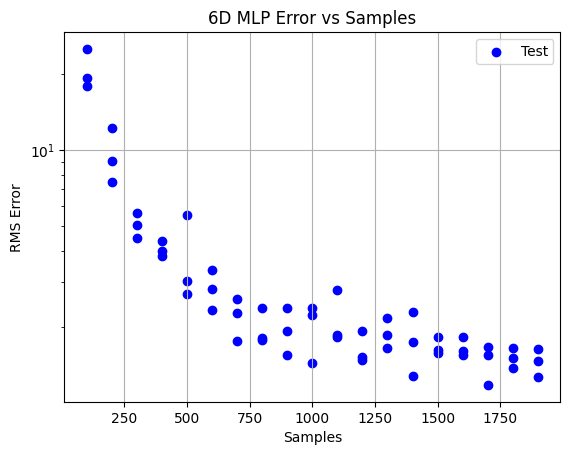

In [ ]:
points_6d = []
model_error_6d = []
training_time_6d = []
evaluation_time_6d = []
points_6d, model_error_6d, evaluation_time_6d, training_time_6d = nn_helpers.generate_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=100,
    sample_high=2001,
    step_size=200,
    seeds=3,
    points=points_6d,
    model_error=model_error_6d,
    training_time=training_time_6d,
    evaluation_time=evaluation_time_6d,
    hidden_layer_size=[30, 30, 10],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=30000,
    output_file="nn_model_comparison_6d.csv",
)
ax = nn_helpers.plot_error_measure(points_6d, model_error_6d, "6D MLP Error vs Samples")
nn_helpers.save_plot(ax, "6D_sweep_mlp")
plt.show()


### 8-Dimensional Dataset

In [12]:
key = "8D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)


Run 8D :: seed 0 :: points 100 :: error 6.4135302903972295 :: train_time 30.185059799987357 
Run 8D :: seed 0 :: points 300 :: error 6.094052657697667 :: train_time 36.33920089999447 
Run 8D :: seed 0 :: points 500 :: error 5.720004857443124 :: train_time 45.51025480002863 
Run 8D :: seed 0 :: points 700 :: error 5.101121888072192 :: train_time 58.33658459997969 
Run 8D :: seed 0 :: points 900 :: error 4.698037598370278 :: train_time 72.91194730001735 
Run 8D :: seed 0 :: points 1100 :: error 6.070937838888683 :: train_time 84.31976800004486 
Run 8D :: seed 0 :: points 1300 :: error 5.813100611471002 :: train_time 96.51494419999653 
Run 8D :: seed 0 :: points 1500 :: error 5.499632703438068 :: train_time 107.7648610000033 
Run 8D :: seed 0 :: points 1700 :: error 4.231269157441181 :: train_time 121.09534700005315 
Run 8D :: seed 0 :: points 1900 :: error 4.355378877660947 :: train_time 135.62265969999135 
Run 8D :: seed 0 :: points 2100 :: error 5.728696667899918 :: train_time 152.0528

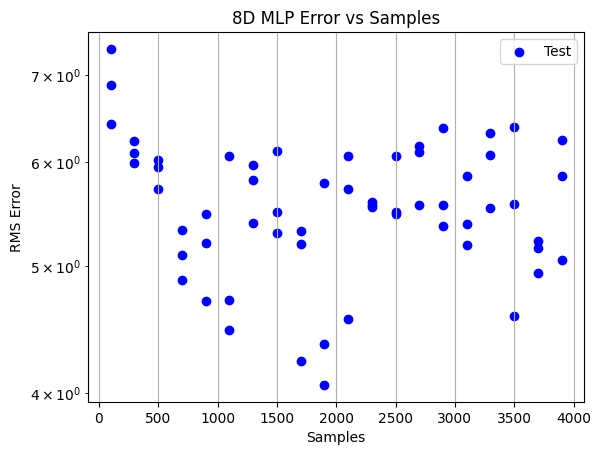

In [ ]:
points_8d = []
model_error_8d = []
training_time_8d = []
evaluation_time_8d = []
points_8d, model_error_8d, evaluation_time_8d, training_time_8d = nn_helpers.generate_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=100,
    sample_high=4000,
    step_size=400,
    seeds=3,
    points=points_8d,
    model_error=model_error_8d,
    training_time=training_time_8d,
    evaluation_time=evaluation_time_8d,
    hidden_layer_size=[30, 30, 10],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=3000,
    output_file="nn_model_comparison_8d.csv",
)
ax = nn_helpers.plot_error_measure(points_8d, model_error_8d, "8D MLP Error vs Samples")
nn_helpers.save_plot(ax, "8D_sweep_mlp")
plt.show()


### 10-Dimensional Dataset

In [14]:
key = "10D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)


Run 10D :: seed 0 :: points 100 :: error 4.429345234108211 :: train_time 261.14672130002873 
Run 10D :: seed 0 :: points 200 :: error 1.3205622194736282 :: train_time 318.0841543000424 
Run 10D :: seed 0 :: points 300 :: error 0.5958228663492201 :: train_time 366.2850762999733 
Run 10D :: seed 0 :: points 400 :: error 0.3411132041682733 :: train_time 423.5071828000364 
Run 10D :: seed 0 :: points 500 :: error 0.3106196403617199 :: train_time 466.99143160000676 
Run 10D :: seed 0 :: points 600 :: error 0.206431777102594 :: train_time 541.4819935999694 
Run 10D :: seed 0 :: points 700 :: error 0.17820232871281078 :: train_time 595.6455261999508 
Run 10D :: seed 0 :: points 800 :: error 0.20027051400361018 :: train_time 643.1839359999867 
Run 10D :: seed 0 :: points 900 :: error 0.1515072083796369 :: train_time 711.2455794999842 
Run 10D :: seed 0 :: points 1000 :: error 0.14236770398470827 :: train_time 753.0796625000075 
Run 10D :: seed 0 :: points 1100 :: error 0.13598532151447507 :: t

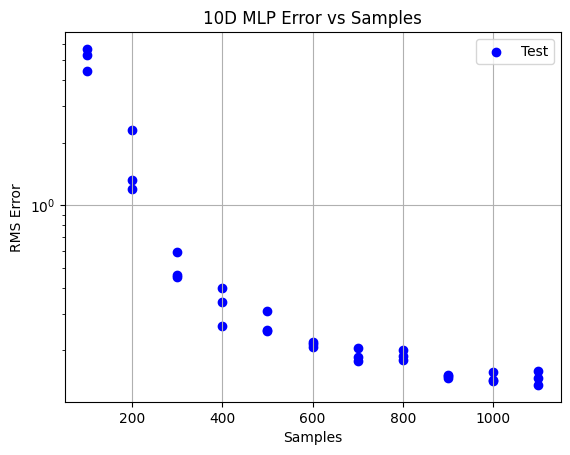

In [15]:
points_10d = []
model_error_10d = []
training_time_10d = []
evaluation_time_10d = []
points_10d, model_error_10d, evaluation_time_10d, training_time_10d = nn_helpers.generate_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=100,
    sample_high=1101,
    step_size=100,
    seeds=3,
    points=points_10d,
    model_error=model_error_10d,
    training_time=training_time_10d,
    evaluation_time=evaluation_time_10d,
    hidden_layer_size=[20, 20, 20],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=30000,
    output_file="nn_model_comparison_10d.csv",
)
ax = nn_helpers.plot_error_measure(points_10d, model_error_10d, "10D MLP Error vs Samples")
nn_helpers.save_plot(ax, "10D_sweep_mlp")
plt.show()
